# Diabetes readmission: exploring more models

NOVA IMS Enterprise Data Science Bootcamp, 2026-27. Davide Corbo.

The question, from the project brief: **at the moment of discharge, how likely is a
diabetic patient to be readmitted in less than 30 days** (`readmitted == "<30"`), so
that the hospital can prioritise its limited follow-up resources?

In this notebook I build the model side of the project: a leakage-safe setup (data,
split, preprocessing, metrics, results log), several model families compared on it,
the steps that turn a score into a decision (calibration, capacity tiers,
explanations, fairness), and the test set opened once at the end.

Two design choices:

- **Everything that learns from the data lives in a scikit-learn `Pipeline`**
  (`src/preprocessing.py`): rare-level grouping, encoding, scaling, the model. The
  pipeline is refitted automatically on the fitting rows of every split, every
  cross-validation fold and every hyperparameter search, so it can never see the rows
  it is scored on. It is also one object, which is what the project plan asks for
  (`pipeline.joblib`: preprocessing + model + calibration).
- **Hyperparameters are tuned with grouped cross-validation on the training rows
  only.** The validation set is used to compare the tuned candidates, never to tune.

The cleaning follows the proposals of the decision log; the alternatives are tested
in `01_cleaning_variants.ipynb`.

The plan of the notebook (✅ ready, 🔲 to do):

| Stage | What | Status |
|---|---|---|
| 0 | Get ready | ✅ |
| 1 | Load and clean, through `src/` | ✅ |
| 2 | Three sets, split by patient | ✅ |
| 3 | Preprocessing as pipelines | ✅ |
| 4 | Grouped cross-validation, results log, two baselines | ✅ |
| 5 | Model families: linear, EBM, bagging, boosting (sklearn, XGBoost, LightGBM, CatBoost), AFT, Keras, ensemble | ✅ |
| 6 | Calibration, capacity tiers, SHAP, fairness | 🔲 |
| 7 | The test set, once | 🔲 locked |

## The leakage rules of this notebook

Every rule below has a check (`assert`) or a design choice that enforces it.

1. **Only row-by-row rules before the split.** `clean` computes nothing from other
   rows (no frequency, mean or threshold).
2. **No patient in two sets.** Every split, every cross-validation fold and every
   hyperparameter search is grouped on `patient_nbr`.
3. **Everything that learns lives inside the pipeline**: rare-level grouping,
   encoding, scaling, imputation, feature selection, target encoding, resampling.
   Nothing is fitted on the whole dataset, nor on train + validation before the end.
4. **No random internal splits.** Early stopping (in scikit-learn, XGBoost, LightGBM,
   CatBoost) holds out a random share of rows *by encounter*, which mixes patients.
   It stays off, or uses an eval set cut with `GroupShuffleSplit` from the fitting
   rows only, never the validation or test set.
5. **Tuning on cross-validation, comparing on validation, test once.** The more
   models are compared on validation, the more optimistic the best validation score
   becomes, so validation is not used for tuning.
6. **No patient-history feature built from the whole file.** Counting a patient's
   other encounters or reading their previous labels uses rows from the future, and
   `encounter_id` is not reliably chronological (decision log, D-004). The history
   known at discharge is already in `number_inpatient`, `number_emergency` and
   `number_outpatient`.
7. **Calibration and thresholds are learned on validation or out-of-fold
   predictions**, never on test.
8. **`readmitted`, `encounter_id` and `patient_nbr` are never features** (D-011,
   D-012); an `assert` checks the feature list.

----------------------------------------------------------------------
# STAGE 0. GET READY
----------------------------------------------------------------------

**0.1** I find the project folder (the first folder above this notebook that has
`src/data_prep.py`) and make `src/` importable. Then I check
Python, the `.venv`, the data, and the model libraries of Stage 5. If one says
`MISSING`, run `python -m pip install -r requirements.txt` with the `.venv` active.

In [1]:
import sys
from datetime import date
from importlib.util import find_spec
from pathlib import Path

PROJECT = next(
    p
    for p in [Path.cwd(), *Path.cwd().parents]
    if (p / "src" / "data_prep.py").exists()
)
sys.path.insert(0, str(PROJECT / "src"))

print("Project folder :", PROJECT)
print("Python 3.13    :", sys.version_info[:2] == (3, 13))
print("Running .venv  :", ".venv" in sys.executable)
print("Data in place  :", (PROJECT / "data" / "diabetic_data.csv").exists())
LIBRARIES = ["xgboost", "lightgbm", "catboost", "interpret", "tensorflow", "shap"]
for package in LIBRARIES:
    print(f"{package:<15}:", "OK" if find_spec(package) else "MISSING")

Project folder : C:\Users\david\Documents\DiabetesProject\Diabetes-Hospital-Readmission-Data-Science-Project
Python 3.13    : True
Running .venv  : True
Data in place  : True
xgboost        : OK
lightgbm       : OK
catboost       : OK
interpret      : OK
tensorflow     : OK
shap           : OK


**0.2** All the imports in one place.

In [2]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy.stats import loguniform, randint
from sklearn.base import clone
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import RandomizedSearchCV, StratifiedGroupKFold
from sklearn.pipeline import Pipeline

from data_prep import add_mapping_descriptions, load_mappings, load_raw
from evaluation import cv_summary, leaderboard, scores
from features import (
    CATEGORICAL,
    DEATH_OR_HOSPICE,
    FEATURES,
    GROUP,
    NUMERIC,
    REFERENCE,
    TARGET,
    clean,
    split_by_patient,
)

SEED = 42  # one seed for the whole project
pd.set_option("display.max_columns", 50)
pd.set_option("display.width", 200)

----------------------------------------------------------------------
# STAGE 1. LOAD AND CLEAN
----------------------------------------------------------------------
**1.1** I load the data only through `src/data_prep.py` (project rule) and apply
`clean` from `src/features.py`, with the proposals of the decision log (D-004 to
D-012). The `assert` lines check the numbers of the decision log (99,343 encounters
of 69,990 patients, `<30` rate 11.39%) and that no identifier, reference column or
target is a feature.

In [3]:
mappings = load_mappings()
raw = add_mapping_descriptions(load_raw(), mappings)

# The death/hospice codes in src must be the ones the lookup table describes
discharge_lookup = pd.Series(mappings["discharge_disposition_id"])
end_of_life = discharge_lookup.str.contains("Expired|Hospice", case=False)
assert sorted(discharge_lookup[end_of_life].index) == DEATH_OR_HOSPICE

df = clean(raw)
assert len(df) == 99_343 and df[GROUP].nunique() == 69_990
assert "readmitted" not in df.columns
assert set(FEATURES + REFERENCE + [TARGET, GROUP]) == set(df.columns)
assert not set(FEATURES) & set(REFERENCE + [TARGET, GROUP])
print(f"{len(raw):,} -> {len(df):,} encounters, {df[GROUP].nunique():,} patients")
print(f"<30 rate: {df[TARGET].mean():.2%}")
print(len(NUMERIC), "numeric and", len(CATEGORICAL), "categorical features")

101,766 -> 99,343 encounters, 69,990 patients
<30 rate: 11.39%
12 numeric and 25 categorical features


----------------------------------------------------------------------
# STAGE 2. THREE SETS, SPLIT BY PATIENT
----------------------------------------------------------------------
**2.1** `split_by_patient` makes two `GroupShuffleSplit` cuts on `patient_nbr` (60 /
20 / 20 of the patients, D-010 option A) and checks that no patient is in two sets.
The sizes are asserted so that the split cannot change silently: it is the split
shared by the whole project, so final test scores from different notebooks are
measured on the very same patients.

The test set is **not** touched until Stage 7: no target, no profile, no plot.

In [4]:
train, val, test = split_by_patient(df, seed=SEED)
assert (len(train), len(val), len(test)) == (59_814, 19_727, 19_802)

X_train, y_train, g_train = train[FEATURES], train[TARGET], train[GROUP]
X_val, y_val = val[FEATURES], val[TARGET]

pd.DataFrame(
    {
        "encounters": [len(train), len(val), len(test)],
        "patients": [part[GROUP].nunique() for part in (train, val, test)],
        "readmitted_30_rate": [train[TARGET].mean(), val[TARGET].mean(), np.nan],
    },
    index=["train", "validation", "test (closed)"],
).round(3)

,encounters,patients,readmitted_30_rate
train,59814,41994,0.114
validation,19727,13998,0.114
test (closed),19802,13998,NaN


----------------------------------------------------------------------
# STAGE 3. PREPROCESSING AS PIPELINES
----------------------------------------------------------------------
**3.1** `make_preprocessor` (in `src/preprocessing.py`) prepares the data for three
families of models with scikit-learn transformers, so it can sit inside a `Pipeline`:

| kind | for | numbers | categories |
|---|---|---|---|
| `linear` | logistic regression, neural networks | standardised | one-hot |
| `onehot` | random forest, XGBoost, LightGBM | as they are | one-hot |
| `ordinal` | histogram gradient boosting (native categories) | as they are | integer codes |

The rare levels are grouped (D-009): for each column, at most
the 10 most frequent levels **of the fitting rows** with at least 100 rows are kept,
and the rest go to one "infrequent" level (`min_frequency` and `max_categories` of
the encoders). A level never seen in the fitting rows goes to that same level
(one-hot) or becomes missing (ordinal). `gender` keeps all its levels, as the brief
asks.

In [5]:
from preprocessing import make_pipeline, make_preprocessor

# The three variants, unfitted: they learn nothing until a pipeline is fitted
{kind: make_preprocessor(kind) for kind in ["linear", "onehot", "ordinal"]}

{'linear': ColumnTransformer(transformers=[('num', StandardScaler(),
                                  ['age_band_order', 'time_in_hospital',
                                   'num_lab_procedures', 'num_procedures',
                                   'num_medications', 'number_diagnoses',
                                   'n_meds_active', 'n_meds_changed',
                                   'number_outpatient', 'number_emergency',
                                   'number_inpatient', 'n_visits_last_year']),
                                 ('cat',
                                  OneHotEncoder(handle_unknown='infrequent_if_exist',
                                                max_catego...
                                   'A1Cresult', 'diag_1_group', 'diag_2_group',
                                   'diag_3_group', 'change', 'diabetesMed',
                                   'metformin', 'repaglinide', 'nateglinide',
                                   'glimepiride', 'glipizide'

----------------------------------------------------------------------
# STAGE 4. GROUPED CROSS-VALIDATION AND THE RESULTS LOG
----------------------------------------------------------------------
**4.1** `CV` is the only cross-validation splitter of the notebook:
`StratifiedGroupKFold` keeps every patient in one fold **and** keeps the `<30` rate
about the same in every fold.
Every search in Stage 5 must receive it together with `groups=g_train`; without the
groups, scikit-learn silently splits by encounter.

`run` fits one pipeline on the training rows and adds a train row and a validation row
to the log. `board` shows the log as a readable ranking (`leaderboard` in
`src/evaluation.py`): one row per model, best first, validation scores shaded from
light (worse) to dark (better), the lift over a random ranking, and the overfitting
gap (train minus validation PR-AUC) as an orange bar. `cv_scores` scores one pipeline
fold by fold on any rows (the pipeline, preprocessing included, is refitted in each
fold).

The log is saved to `reports/experiments-readmission-dc.csv` in step 5.13.

In [6]:
CV = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=SEED)
LOG = PROJECT / "reports" / "experiments-readmission-dc.csv"
today = date.today().isoformat()
results = []  # one dict per (model, dataset)
fitted = {}  # name -> fitted pipeline
pipelines = {}  # name -> unfitted pipeline, to refit in cross-validation and Stage 7


def show():
    """The raw results log: every model tested so far, on train and validation."""
    return pd.DataFrame(results).round(3)


def board(family=None):
    """The results log as a readable ranking of the models (validation scores)."""
    return leaderboard(pd.DataFrame(results), y_val.mean(), family)


def run(name, pipe, family="", note=""):
    """Fit one pipeline on train, score it on train and validation, log it."""
    model = clone(pipe).fit(X_train, y_train)
    fitted[name], pipelines[name] = model, pipe
    for dataset, X, y in [("train", X_train, y_train), ("validation", X_val, y_val)]:
        p = model.predict_proba(X)[:, 1]
        row = {"date": today, "model": name, "family": family, "dataset": dataset}
        results.append(row | scores(y, p) | {"note": note})
    return board()


def cv_scores(pipe, rows):
    """Score one pipeline fold by fold on `rows`, refitting it inside every fold."""
    out = []
    folds = CV.split(rows, rows[TARGET], groups=rows[GROUP])
    for fold, (fit_idx, score_idx) in enumerate(folds, start=1):
        fit_rows, score_rows = rows.iloc[fit_idx], rows.iloc[score_idx]
        assert not set(fit_rows[GROUP]) & set(score_rows[GROUP])
        model = clone(pipe).fit(fit_rows[FEATURES], fit_rows[TARGET])
        p = model.predict_proba(score_rows[FEATURES])[:, 1]
        out.append({"fold": fold} | scores(score_rows[TARGET], p))
    return pd.DataFrame(out)

**4.2 Two baselines.** Every new model must beat them on validation:

- A **logistic regression** (L2): the simplest model to explain to a doctor, and the
  interpretable baseline of the project plan.
- A **histogram gradient boosting** with fixed, conservative hyperparameters (small
  trees, at least 200 encounters per leaf, low learning rate) and native categories.
  Its early stopping stays **off**: it would hold out a random 10% of the training
  rows by encounter, mixing patients (rule 4). Step 5.1 tunes it.

Both use `class_weight="balanced"` against the ~11% imbalance, as the project plan
asks (class weights rather than oversampling).

In [7]:
baselines = {
    "Logistic regression (baseline)": make_pipeline(
        "linear", LogisticRegression(C=1.0, class_weight="balanced", max_iter=2000)
    ),
    "Gradient boosting (baseline)": make_pipeline(
        "ordinal",
        HistGradientBoostingClassifier(
            learning_rate=0.05,
            max_iter=150,
            max_leaf_nodes=15,
            min_samples_leaf=200,
            l2_regularization=1.0,
            categorical_features=CATEGORICAL,
            class_weight="balanced",
            early_stopping=False,
            random_state=SEED,
        ),
    ),
}
for (name, pipe), family in zip(baselines.items(), ["linear", "boosting"]):
    run(name, pipe, family=family, note="baseline")
board()

,Family,PR-AUC,Lift,ROC-AUC,Precision top 10%,Recall top 10%,Train PR-AUC,Overfitting gap
Gradient boosting (baseline),boosting,0.224,1.96x,0.674,0.264,0.231,0.268,0.043
Logistic regression (baseline),linear,0.210,1.84x,0.658,0.247,0.216,0.218,0.009


----------------------------------------------------------------------
# STAGE 5. MODEL FAMILIES
----------------------------------------------------------------------
**5.0 What kind of problem is this?** A **binary classification** with a rare
positive class: `readmitted_30` is 1 for about 11% of the encounters. The hospital
does not need a yes/no answer but a **ranking** of the discharged patients (who gets
the limited follow-up calls) and, after calibration, a **probability** it can trust.
That is why the models are compared on PR-AUC and top-10% precision/recall, not on
accuracy.

Two other framings, and why they reduce to this one:

- **Survival analysis** (time to readmission). The data has no readmission dates,
  only "<30", ">30" and "NO", so the time is only known to be below or above 30 days.
  A survival model such as the **AFT** (accelerated failure time) can still be
  trained on these interval-censored times (5.9), but with this information it is a
  binary classifier with a different link function: it can only differ from the
  others by the way it weights the errors.
- **Three classes** (NO / >30 / <30). The ">30" level could help as an extra signal
  (an ordinal or multiclass model, scored on P(<30)). Not tested yet: it needs the
  raw `readmitted` column as an auxiliary target, never as a feature.

**The families tested here.** Each one gets a first version and, for the strongest,
a random search on the grouped cross-validation of the training rows:

| Family | Models | Preprocessing | Step |
|---|---|---|---|
| Linear | Logistic regression L2 (baseline), elastic net | `linear` | 4.2, 5.2 |
| Glass-box additive | Explainable Boosting Machine (EBM) | none (native categories) | 5.3 |
| Bagged trees | Random forest, extra trees | `onehot` | 5.4 |
| Gradient boosting | scikit-learn (tuned), XGBoost, LightGBM, CatBoost | `ordinal`, `onehot`, none | 5.5–5.8 |
| Survival | XGBoost AFT, read as P(readmitted within 30 days) | `onehot` | 5.9 |
| Neural networks | Keras multi-layer perceptron | `linear` | 5.10 |
| Ensemble | Soft voting of the best model of three families | each member's own | 5.11 |

**Not tested, and why:**

- *k-nearest neighbours*: distances over ~150 one-hot columns carry little meaning,
  and scoring needs the whole training set at every prediction.
- *Kernel SVM*: does not scale to 60,000 rows and gives no native probabilities.
- *Naive Bayes*: assumes independent features, while the medication, `change` and
  `diabetesMed` columns are strongly tied (see the EDA).
- *Stacking* (`StackingClassifier`): its internal cross-validation splits by
  encounter, not by patient, so the meta-model would learn from leaked out-of-fold
  predictions. Soft voting (5.11) has no internal split.
- *Tabular foundation models from Hugging Face* (e.g. TabPFN): row limit (the
  context must be a sample of training patients), GPU, licence. A possible last
  experiment.

**Running time.** About 45 minutes on a 12-core laptop with the `N_ITER` below: most of
it is CatBoost (about a minute per fit) and the fold-by-fold check of 5.12. With one
combination per search the whole notebook takes about 25 minutes. `N_ITER` sets the
number of combinations tried per family; 0 skips that search and keeps the first
version.

In [8]:
import os

os.environ.setdefault("TF_CPP_MIN_LOG_LEVEL", "2")  # quieter TensorFlow

from interpret.glassbox import ExplainableBoostingClassifier
from lightgbm import LGBMClassifier
from scipy.stats import uniform
from sklearn.ensemble import (
    ExtraTreesClassifier,
    RandomForestClassifier,
    VotingClassifier,
)
from xgboost import XGBClassifier

from models import CatBoostNativeClassifier, KerasMLPClassifier, XGBAFTClassifier

N_ITER = {
    "hgb": 10,
    "xgboost": 15,
    "lightgbm": 15,
    "catboost": 4,
    "aft": 10,
    "keras": 6,
}
searches = {}  # name -> fitted RandomizedSearchCV, to inspect later


def raw_features(model):
    """A pipeline with no preprocessing, for models that read the categories natively."""
    return Pipeline([("model", model)])


def tune(name, pipe, space, n_iter, family, note=""):
    """Random search on the grouped CV of the training rows, then log the best.

    Every combination is scored by `CV` with `groups=g_train`, the whole pipeline
    (preprocessing included) being refitted in each fold. The best combination is then
    fitted on all the training rows by `run` and scored on train and validation.

    Args:
        name (str): The model name in the log.
        pipe (Pipeline): The unfitted pipeline whose `model__` parameters are searched.
        space (dict): Parameter name -> list or scipy distribution.
        n_iter (int): Combinations to try; 0 skips the search and logs `pipe` as is.
        family (str): The model family, for the log and the ensemble of 5.11.
        note (str): A note for the log.

    Returns:
        Pipeline: The unfitted pipeline with the best parameters.
    """
    if n_iter == 0:
        run(name, pipe, family=family, note=note or "not tuned")
        return pipe
    search = RandomizedSearchCV(
        pipe,
        param_distributions=space,
        n_iter=n_iter,
        scoring="average_precision",
        cv=CV,
        refit=False,  # `run` refits the best combination on the training rows
        random_state=SEED,
    )
    search.fit(X_train, y_train, groups=g_train)
    searches[name] = search
    best = clone(pipe).set_params(**search.best_params_)
    run(name, best, family=family, note=note or f"random search {n_iter}")
    summary = {
        "CV PR-AUC (train, best of search)": search.best_score_,
        "Validation PR-AUC": results[-1]["pr_auc"],
    } | {k.replace("model__", ""): v for k, v in search.best_params_.items()}
    readable = {
        k: f"{v:.4g}" if isinstance(v, float) else str(v) for k, v in summary.items()
    }
    display(pd.Series(readable).to_frame(f"{name}: {n_iter} combinations"))
    return best

**5.1 Tuned scikit-learn gradient boosting.** The baseline's hyperparameters were set
by hand. Here a random search tries `N_ITER["hgb"]` combinations. The same template
is used for every search: the pipeline goes in whole, `cv=CV`, `groups=g_train`.

In [9]:
tuned = {}
tuned["hgb"] = tune(
    "Gradient boosting sklearn (tuned)",
    baselines["Gradient boosting (baseline)"],
    {
        "model__learning_rate": loguniform(0.02, 0.2),
        "model__max_iter": randint(100, 400),
        "model__max_leaf_nodes": randint(8, 32),
        "model__min_samples_leaf": randint(50, 400),
        "model__l2_regularization": loguniform(0.1, 10),
    },
    N_ITER["hgb"],
    family="boosting",
)

,Gradient boosting sklearn (tuned): 10 combinations
"CV PR-AUC (train, best of search)",0.2251
Validation PR-AUC,0.2245
l2_regularization,0.1076
learning_rate,0.03403
max_iter,191
max_leaf_nodes,22
min_samples_leaf,313


**5.2 Elastic-net logistic regression.** A mix of the L1 penalty (which can set
weights to exactly 0, selecting features) and L2 (which shrinks them). Still a linear
model, as easy to explain as the baseline. The `saga` solver is slow on 60,000 rows
(about 30 seconds), so it is not searched.

In [10]:
run(
    "Logistic regression (elastic net)",
    make_pipeline(
        "linear",
        LogisticRegression(
            C=0.1,
            l1_ratio=0.5,
            solver="saga",
            class_weight="balanced",
            max_iter=3000,
        ),
    ),
    family="linear",
)

,Family,PR-AUC,Lift,ROC-AUC,Precision top 10%,Recall top 10%,Train PR-AUC,Overfitting gap
Gradient boosting sklearn (tuned),boosting,0.224,1.97x,0.676,0.266,0.233,0.276,0.051
Gradient boosting (baseline),boosting,0.224,1.96x,0.674,0.264,0.231,0.268,0.043
Logistic regression (elastic net),linear,0.210,1.84x,0.659,0.249,0.218,0.218,0.008
Logistic regression (baseline),linear,0.210,1.84x,0.658,0.247,0.216,0.218,0.009


**5.3 Explainable Boosting Machine (EBM).** A generalised additive model learned by
boosting: the risk is a sum of one curve per feature plus a few pairwise
interactions, each of which can be plotted. That makes it the most interpretable
model after the logistic regression, often with boosting-level accuracy, which
matters for clinicians. It reads the categories natively. It has no class weights,
which does not change a ranking (PR-AUC, ROC-AUC, top-10%).

In [11]:
run(
    "EBM",
    raw_features(ExplainableBoostingClassifier(random_state=SEED)),
    family="additive",
)

,Family,PR-AUC,Lift,ROC-AUC,Precision top 10%,Recall top 10%,Train PR-AUC,Overfitting gap
Gradient boosting sklearn (tuned),boosting,0.224,1.97x,0.676,0.266,0.233,0.276,0.051
Gradient boosting (baseline),boosting,0.224,1.96x,0.674,0.264,0.231,0.268,0.043
EBM,additive,0.221,1.94x,0.667,0.258,0.226,0.262,0.041
Logistic regression (elastic net),linear,0.210,1.84x,0.659,0.249,0.218,0.218,0.008
Logistic regression (baseline),linear,0.210,1.84x,0.658,0.247,0.216,0.218,0.009


**5.4 Bagged trees.** A random forest and its more random variant, extra trees
(split thresholds drawn at random), both with leaves of at least 20 encounters so
that a leaf is never a single patient.

In [12]:
for name, forest in [
    ("Random forest", RandomForestClassifier),
    ("Extra trees", ExtraTreesClassifier),
]:
    run(
        name,
        make_pipeline(
            "onehot",
            forest(
                n_estimators=300,
                min_samples_leaf=20,
                max_features="sqrt",
                class_weight="balanced",
                n_jobs=-1,
                random_state=SEED,
            ),
        ),
        family="bagging",
    )
board()

,Family,PR-AUC,Lift,ROC-AUC,Precision top 10%,Recall top 10%,Train PR-AUC,Overfitting gap
Gradient boosting sklearn (tuned),boosting,0.224,1.97x,0.676,0.266,0.233,0.276,0.051
Gradient boosting (baseline),boosting,0.224,1.96x,0.674,0.264,0.231,0.268,0.043
EBM,additive,0.221,1.94x,0.667,0.258,0.226,0.262,0.041
Logistic regression (elastic net),linear,0.210,1.84x,0.659,0.249,0.218,0.218,0.008
Logistic regression (baseline),linear,0.210,1.84x,0.658,0.247,0.216,0.218,0.009
Random forest,bagging,0.208,1.82x,0.674,0.253,0.222,0.413,0.205
Extra trees,bagging,0.202,1.77x,0.660,0.233,0.204,0.526,0.325


**5.5 XGBoost** (project plan: "gradient-boosted trees, XGBoost / LightGBM").
One-hot preprocessing and a fixed number of trees, no early stopping (rule 4).
`scale_pos_weight` weights the positives: in the first version it is the ratio of
negatives to positives of the training rows (~7.8, the same effect as balanced class
weights); in the search it is just one more hyperparameter.

In [13]:
ratio = (y_train == 0).sum() / (y_train == 1).sum()
tuned["xgboost"] = tune(
    "XGBoost (tuned)",
    make_pipeline(
        "onehot",
        XGBClassifier(
            n_estimators=300,
            learning_rate=0.05,
            max_depth=4,
            subsample=0.8,
            colsample_bytree=0.8,
            scale_pos_weight=ratio,
            tree_method="hist",
            random_state=SEED,
            n_jobs=-1,
        ),
    ),
    {
        "model__n_estimators": randint(150, 600),
        "model__learning_rate": loguniform(0.01, 0.2),
        "model__max_depth": randint(2, 7),
        "model__min_child_weight": loguniform(1, 50),
        "model__subsample": uniform(0.6, 0.4),
        "model__colsample_bytree": uniform(0.5, 0.5),
        "model__reg_lambda": loguniform(0.1, 20),
        "model__scale_pos_weight": uniform(1, 9),
    },
    N_ITER["xgboost"],
    family="boosting",
)

,XGBoost (tuned): 15 combinations
"CV PR-AUC (train, best of search)",0.2248
Validation PR-AUC,0.2263
colsample_bytree,0.8421
learning_rate,0.03738
max_depth,5
min_child_weight,6.939
n_estimators,580
reg_lambda,0.2506
scale_pos_weight,4.52
subsample,0.6729


**5.6 LightGBM.** Same idea as XGBoost, with leaf-wise trees; usually the fastest.

In [14]:
tuned["lightgbm"] = tune(
    "LightGBM (tuned)",
    make_pipeline(
        "onehot",
        LGBMClassifier(
            n_estimators=300,
            learning_rate=0.05,
            num_leaves=15,
            min_child_samples=200,
            subsample=0.8,
            subsample_freq=1,
            colsample_bytree=0.8,
            class_weight="balanced",
            random_state=SEED,
            verbose=-1,
        ),
    ),
    {
        "model__n_estimators": randint(150, 600),
        "model__learning_rate": loguniform(0.01, 0.2),
        "model__num_leaves": randint(8, 64),
        "model__min_child_samples": randint(50, 500),
        "model__subsample": uniform(0.6, 0.4),
        "model__colsample_bytree": uniform(0.5, 0.5),
        "model__reg_lambda": loguniform(0.1, 20),
    },
    N_ITER["lightgbm"],
    family="boosting",
)

,LightGBM (tuned): 15 combinations
"CV PR-AUC (train, best of search)",0.222
Validation PR-AUC,0.2223
colsample_bytree,0.7126
learning_rate,0.01864
min_child_samples,309
n_estimators,459
num_leaves,36
reg_lambda,17.02
subsample,0.9101


**5.7 CatBoost** (through `CatBoostNativeClassifier` in `src/models.py`, which
makes it clonable by scikit-learn). Built for many categorical columns: it reads the
category strings
directly and encodes them with *ordered* target statistics, computed only on the
rows it is fitted on (inside each fold, never on validation or test), and it also
builds combinations of categories. No rare-level grouping or one-hot is needed. It is
the slowest model here (about a minute per fit), so its search is short.

In [15]:
tuned["catboost"] = tune(
    "CatBoost (tuned)",
    raw_features(CatBoostNativeClassifier(random_state=SEED)),
    {
        "model__iterations": randint(300, 700),
        "model__learning_rate": loguniform(0.02, 0.15),
        "model__depth": randint(4, 8),
        "model__l2_leaf_reg": loguniform(1, 20),
    },
    N_ITER["catboost"],
    family="boosting",
)

,CatBoost (tuned): 4 combinations
"CV PR-AUC (train, best of search)",0.2249
Validation PR-AUC,0.2221
depth,6
iterations,449
l2_leaf_reg,1.184
learning_rate,0.08567


**5.8 The boosting libraries side by side.** Four implementations of the same idea;
the differences between them are usually smaller than the effect of their
hyperparameters.

In [16]:
board("boosting")

,Family,PR-AUC,Lift,ROC-AUC,Precision top 10%,Recall top 10%,Train PR-AUC,Overfitting gap
XGBoost (tuned),boosting,0.226,1.98x,0.669,0.267,0.234,0.393,0.167
Gradient boosting sklearn (tuned),boosting,0.224,1.97x,0.676,0.266,0.233,0.276,0.051
Gradient boosting (baseline),boosting,0.224,1.96x,0.674,0.264,0.231,0.268,0.043
LightGBM (tuned),boosting,0.222,1.95x,0.675,0.267,0.234,0.290,0.068
CatBoost (tuned),boosting,0.222,1.95x,0.668,0.262,0.229,0.313,0.091


**5.9 Survival: XGBoost AFT.** `XGBAFTClassifier` (`src/models.py`) trains XGBoost
with the `survival:aft` objective on interval-censored times: T in [0, 30] days for
a readmission within 30 days, T in [30, +inf) otherwise. It returns
P(T <= 30) = F((log 30 - f(x)) / sigma). The search also chooses the distribution of
the error term (normal, logistic or extreme value) and its scale `sigma`.

One detail found while testing: boosting must start from a time of 30 days
(`base_score`). With XGBoost's default start (0.5 days) and a small `sigma`, the
training diverged and gave every patient the same score (PR-AUC 0.114, the base
rate). The wrapper now starts at 30 days, caps each update (`max_delta_step`) and
warns if the training diverges anyway.

In [17]:
tuned["aft"] = tune(
    "XGBoost AFT (tuned)",
    make_pipeline("onehot", XGBAFTClassifier(random_state=SEED)),
    {
        "model__distribution": ["normal", "logistic", "extreme"],
        "model__sigma": loguniform(0.5, 2),
        "model__n_estimators": randint(150, 600),
        "model__learning_rate": loguniform(0.01, 0.2),
        "model__max_depth": randint(2, 7),
        "model__min_child_weight": loguniform(1, 50),
    },
    N_ITER["aft"],
    family="survival",
)

,XGBoost AFT (tuned): 10 combinations
"CV PR-AUC (train, best of search)",0.2257
Validation PR-AUC,0.2232
distribution,extreme
learning_rate,0.1087
max_depth,4
min_child_weight,21.12
n_estimators,170
sigma,0.6207


**5.10 Neural network: Keras multi-layer perceptron.** `KerasMLPClassifier`
(`src/models.py`) wraps a Keras network (TensorFlow backend) as a scikit-learn
classifier, so it uses the same pipeline (`linear` preprocessing: scaled numbers,
one-hot categories) and the same grouped search. Dense layers with ReLU, dropout and
an L2 penalty against overfitting, balanced class weights.

Keras' usual `validation_split` + early stopping would hold out the **last rows by
encounter**, mixing patients (rule 4). So the network trains for a fixed number of
epochs, and `epochs` is tuned by the grouped search like any other hyperparameter.

In [18]:
tuned["keras"] = tune(
    "Keras MLP (tuned)",
    make_pipeline("linear", KerasMLPClassifier(random_state=SEED)),
    {
        "model__hidden": [(32,), (64,), (64, 32), (128, 64)],
        "model__dropout": uniform(0.0, 0.5),
        "model__l2": loguniform(1e-5, 1e-2),
        "model__learning_rate": loguniform(3e-4, 3e-3),
        "model__epochs": randint(5, 30),
    },
    N_ITER["keras"],
    family="neural",
)

,Keras MLP (tuned): 6 combinations
"CV PR-AUC (train, best of search)",0.2189
Validation PR-AUC,0.2222
dropout,0.3058
epochs,16
hidden,"(32,)"
l2,7.476e-05
learning_rate,0.001227


**5.11 Soft-voting ensemble.** The average of the probabilities of the best model
(on validation) of the three best families. Different families make different
mistakes, so their average can rank better than each of them. Each member keeps its
own pipeline, all fitted on the same training rows; there is no internal split, so
no leakage. Choosing the members on validation is a comparison, like every row of
the log, and is checked again in 5.12.

In [19]:
validation = show().query("dataset == 'validation' and note != 'baseline'")
best_per_family = (
    validation.sort_values("pr_auc", ascending=False).groupby("family").head(1)
)
members = list(best_per_family["model"][:3])
print("Ensemble members:", members)
run(
    "Soft-voting ensemble",
    VotingClassifier(
        [(f"m{i}", pipelines[name]) for i, name in enumerate(members)],
        voting="soft",
    ),
    family="ensemble",
    note=" + ".join(members),
)

Ensemble members: ['XGBoost (tuned)', 'XGBoost AFT (tuned)', 'Keras MLP (tuned)']


,Family,PR-AUC,Lift,ROC-AUC,Precision top 10%,Recall top 10%,Train PR-AUC,Overfitting gap
Soft-voting ensemble,ensemble,0.229,2.00x,0.676,0.269,0.236,0.330,0.101
XGBoost (tuned),boosting,0.226,1.98x,0.669,0.267,0.234,0.393,0.167
Gradient boosting sklearn (tuned),boosting,0.224,1.97x,0.676,0.266,0.233,0.276,0.051
Gradient boosting (baseline),boosting,0.224,1.96x,0.674,0.264,0.231,0.268,0.043
XGBoost AFT (tuned),survival,0.223,1.95x,0.671,0.273,0.239,0.312,0.089
LightGBM (tuned),boosting,0.222,1.95x,0.675,0.267,0.234,0.290,0.068
Keras MLP (tuned),neural,0.222,1.95x,0.673,0.258,0.226,0.250,0.027
CatBoost (tuned),boosting,0.222,1.95x,0.668,0.262,0.229,0.313,0.091
EBM,additive,0.221,1.94x,0.667,0.258,0.226,0.262,0.041
Logistic regression (elastic net),linear,0.210,1.84x,0.659,0.249,0.218,0.218,0.008


**5.12 Is the gain real?** The validation set is one sample of patients, and many
models were compared on it. Before choosing, the 3 best models on validation and the
logistic regression baseline are scored **fold by fold on train + validation** with
`cv_scores` (grouped, preprocessing refitted in every fold; the test set stays
closed). Rule: a model wins over a simpler one only if it beats it in at least 4 of
the 5 folds; otherwise it is a tie and the simpler model is preferred. This cell
takes several minutes if CatBoost or the ensemble are in the shortlist.

In [20]:
dev = pd.concat([train, val])
ranking = show().query("dataset == 'validation'").sort_values("pr_auc", ascending=False)
shortlist = list(ranking["model"][:3])
if "Logistic regression (baseline)" not in shortlist:
    shortlist.append("Logistic regression (baseline)")
print("Cross-validated:", shortlist)

cv = pd.concat(
    [cv_scores(pipelines[name], dev).assign(model=name) for name in shortlist]
)
cv_summary(cv)

Cross-validated: ['Soft-voting ensemble', 'XGBoost (tuned)', 'Gradient boosting (baseline)', 'Logistic regression (baseline)']


,PR-AUC,ROC-AUC,Precision top 10%,Recall top 10%
Soft-voting ensemble,0.230 ± 0.003,0.676 ± 0.007,0.274 ± 0.006,0.239 ± 0.005
XGBoost (tuned),0.228 ± 0.004,0.673 ± 0.006,0.275 ± 0.004,0.240 ± 0.003
Gradient boosting (baseline),0.226 ± 0.005,0.675 ± 0.008,0.269 ± 0.005,0.235 ± 0.005
Logistic regression (baseline),0.213 ± 0.002,0.662 ± 0.007,0.255 ± 0.007,0.223 ± 0.006


The same folds as a chart: one line per model, one point per fold. Lines that never
cross mean the ranking is stable; lines that cross mean the difference is luck.

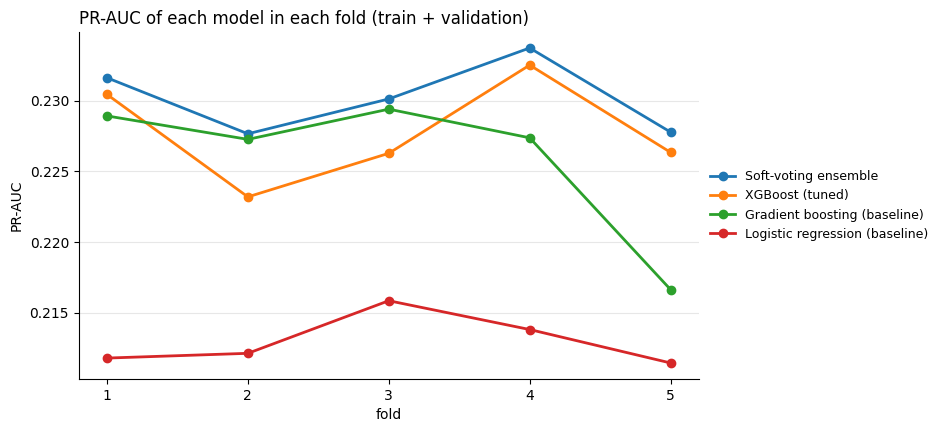

In [21]:
by_fold = cv.pivot(index="fold", columns="model", values="pr_auc")
order = by_fold.mean().sort_values(ascending=False).index
fig, ax = plt.subplots(figsize=(8, 4.5))
for name in order:
    ax.plot(by_fold.index, by_fold[name], marker="o", linewidth=2, label=name)
ax.set_xticks(by_fold.index)
ax.set_xlabel("fold")
ax.set_ylabel("PR-AUC")
ax.set_title("PR-AUC of each model in each fold (train + validation)", loc="left")
ax.legend(frameon=False, fontsize=9, loc="center left", bbox_to_anchor=(1, 0.5))
for side in ["top", "right"]:
    ax.spines[side].set_visible(False)
ax.grid(axis="y", alpha=0.3)
plt.show()

The decision rule, model by model: in how many folds does the top model beat it, and
by how much on average?

In [22]:
top = order[0]
difference = by_fold.drop(columns=top).rsub(by_fold[top], axis=0)
pd.DataFrame(
    {
        f"Folds won by {top} (of 5)": (difference > 0).sum(),
        "Mean PR-AUC difference": difference.mean(),
        "Verdict": np.where(
            (difference > 0).sum() >= 4, f"{top} wins", "tie: prefer the simpler"
        ),
    }
).style.format("{:.4f}", subset=["Mean PR-AUC difference"])

,Folds won by Soft-voting ensemble (of 5),Mean PR-AUC difference,Verdict
model,,,
Gradient boosting (baseline),5,0.0043,Soft-voting ensemble wins
Logistic regression (baseline),5,0.0172,Soft-voting ensemble wins
XGBoost (tuned),5,0.0024,Soft-voting ensemble wins


**5.13** The log, saved to `reports/experiments-readmission-dc.csv`; every model on
validation as a chart (the axis starts at 0.19 to make the small differences
visible); and the final ranking.

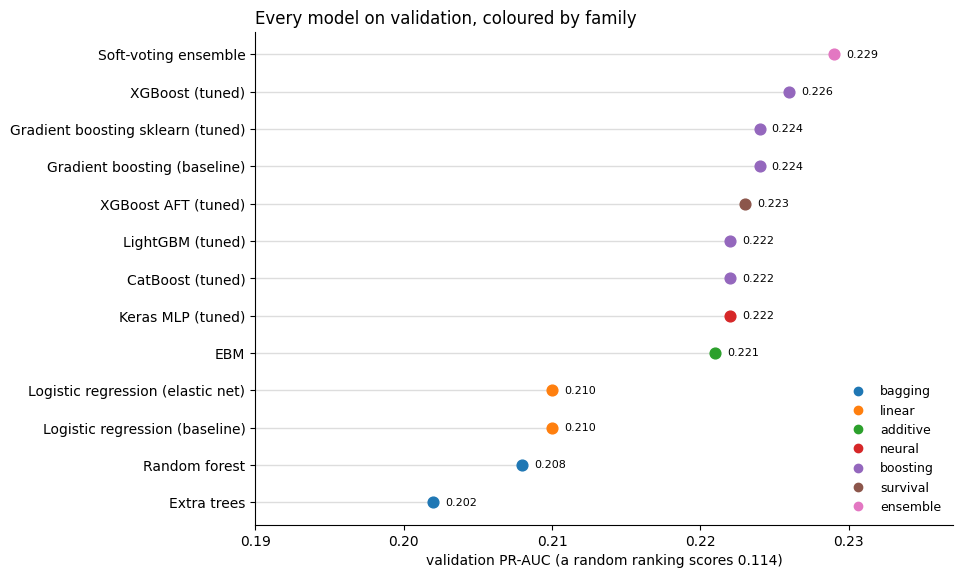

,Family,PR-AUC,Lift,ROC-AUC,Precision top 10%,Recall top 10%,Train PR-AUC,Overfitting gap
Soft-voting ensemble,ensemble,0.229,2.00x,0.676,0.269,0.236,0.330,0.101
XGBoost (tuned),boosting,0.226,1.98x,0.669,0.267,0.234,0.393,0.167
Gradient boosting sklearn (tuned),boosting,0.224,1.97x,0.676,0.266,0.233,0.276,0.051
Gradient boosting (baseline),boosting,0.224,1.96x,0.674,0.264,0.231,0.268,0.043
XGBoost AFT (tuned),survival,0.223,1.95x,0.671,0.273,0.239,0.312,0.089
LightGBM (tuned),boosting,0.222,1.95x,0.675,0.267,0.234,0.290,0.068
Keras MLP (tuned),neural,0.222,1.95x,0.673,0.258,0.226,0.250,0.027
CatBoost (tuned),boosting,0.222,1.95x,0.668,0.262,0.229,0.313,0.091
EBM,additive,0.221,1.94x,0.667,0.258,0.226,0.262,0.041
Logistic regression (elastic net),linear,0.210,1.84x,0.659,0.249,0.218,0.218,0.008


In [23]:
show().to_csv(LOG, index=False)

on_val = show().query("dataset == 'validation'").set_index("model")
on_val = on_val.sort_values("pr_auc")
families = list(dict.fromkeys(on_val["family"]))
colours = dict(zip(families, plt.cm.tab10.colors))
fig, ax = plt.subplots(figsize=(9, 0.4 * len(on_val) + 1.2))
for i, (name, row) in enumerate(on_val.iterrows()):
    ax.plot([0.19, row["pr_auc"]], [i, i], color="#dddddd", linewidth=1, zorder=1)
    ax.scatter(row["pr_auc"], i, color=colours[row["family"]], s=60, zorder=2)
    ax.text(row["pr_auc"] + 0.0008, i, f"{row['pr_auc']:.3f}", va="center", fontsize=8)
ax.set_yticks(range(len(on_val)), on_val.index)
ax.set_xlim(0.19, on_val["pr_auc"].max() + 0.008)
ax.set_xlabel(f"validation PR-AUC (a random ranking scores {y_val.mean():.3f})")
ax.set_title("Every model on validation, coloured by family", loc="left")
handles = [
    plt.Line2D([], [], marker="o", linestyle="", color=c, label=f)
    for f, c in colours.items()
]
ax.legend(handles=handles, frameon=False, fontsize=9, loc="lower right")
for side in ["top", "right"]:
    ax.spines[side].set_visible(False)
plt.show()
board()

**5.14 What the comparison says.** (Numbers from my run; with `SEED = 42` they come out the same every time.)

- **Every family lands in the same narrow band.** On validation, all models except the bagged trees are between 0.210 and 0.229 PR-AUC (base rate 0.114) and between 0.658 and 0.676 ROC-AUC. The data, not the algorithm, sets the ceiling: there are no lab values over time, no notes and no social information.
- **Boosting beats the linear model, consistently.** On the fold-by-fold check of 5.12 (train + validation), the scikit-learn gradient boosting baseline beats the logistic regression in 5 of 5 folds (PR-AUC 0.226 vs 0.213).
- **Tuned XGBoost is the best single model** (cross-validated PR-AUC 0.228 ± 0.004), ahead of the boosting baseline in every fold, but by only 0.002 on average. LightGBM, CatBoost and the scikit-learn boosting are within 0.004 of it on validation: once tuned, the boosting libraries are interchangeable here.
- **The AFT survival model works as well as the classifiers** (validation PR-AUC 0.223 and the best top-10% recall, 0.239). That is what to expect: without readmission dates it can only be a binary model with another link function. It is not better, but its probabilities have a time interpretation that the report can use.
- **The Keras network** (one hidden layer of 32 neurons, 16 epochs) reaches 0.222, at the level of the boosting libraries and above the logistic regression, but not above XGBoost.
- **EBM** reaches 0.221 with a fully readable model (one curve per feature): only 0.005 behind XGBoost on validation, a strong candidate if the clinicians need to see *why*.
- **Bagged trees are the weakest** and overfit the most (random forest: 0.413 on train, 0.208 on validation).
- **The soft-voting ensemble** (XGBoost + AFT + Keras) is the top model: cross-validated PR-AUC 0.230 ± 0.003, and it beats every other candidate in 5 of 5 folds. By the rule of 5.12 it wins. But its lead over XGBoost alone is 0.0024 PR-AUC, below the 0.005 that matters in practice, and it is three models to calibrate, explain (SHAP) and serve instead of one.

**Proposal for the choice:** **XGBoost (tuned)** as the production model, simpler to calibrate, explain and deploy, with the ensemble kept as the challenger to report. **EBM** is the interpretable alternative to show the clinicians. Before the test set (Stage 7), Stage 6 must calibrate the chosen model and build the capacity tiers on validation.

**Two caveats.** The shortlist and the ensemble members were chosen on validation, and 5.12 cross-validates on train + validation, so these numbers are slightly optimistic; the test set opened once in Stage 7 will tell by how much. The searches are short (4 to 15 combinations per family): longer searches could move any single model by a few thousandths, not change the picture.

----------------------------------------------------------------------
# STAGE 6. FROM A SCORE TO A DECISION (to do)
----------------------------------------------------------------------
What the project plan asks for Phase 2, on the chosen pipeline, using **validation or
out-of-fold predictions only**:

- **6.1 Calibration.** With balanced class weights the probabilities are inflated.
  Wrap the fitted pipeline in `CalibratedClassifierCV(FrozenEstimator(model),
  method="isotonic")`, fit it on validation, and draw a reliability curve
  (`CalibrationDisplay`). Then a "20% risk" means roughly 20%.
- **6.2 Capacity tiers.** High / Medium / Low cutoffs set by follow-up capacity
  (e.g. top 10% and top 30% of validation scores), not by 0.5: for each capacity,
  the threshold, the precision and the share of readmissions caught.
- **6.3 Decision curve** (net benefit against the threshold), on validation.
- **6.4 SHAP** for the winner: global importance and per-patient reasons for the
  hospital worklist (`shap` is in `requirements.txt`).
- **6.5 Fairness baseline**: PR-AUC and top-10% recall by `race`, `age` band and
  `gender` (not reporting the 3 `Unknown/Invalid` gender encounters, as the brief
  says).

----------------------------------------------------------------------
# STAGE 7. THE TEST SET, ONCE (locked)
----------------------------------------------------------------------
Only after the choice of 5.6 and the calibration of 6.1. The chosen pipeline is
refitted on train + validation (preprocessing included, because it is inside the
pipeline), scored once on test, and the row is added to the log with the note
"test opened once". Nothing is chosen or changed after this cell. To open it, set
`OPEN_TEST = True` and `CHOSEN` to the winner's name.

In [24]:
OPEN_TEST = False
CHOSEN = None

if OPEN_TEST:
    dev = pd.concat([train, val])
    final = clone(pipelines[CHOSEN]).fit(dev[FEATURES], dev[TARGET])
    p_test = final.predict_proba(test[FEATURES])[:, 1]
    results.append(
        {"date": today, "model": CHOSEN, "family": "", "dataset": "test"}
        | scores(test[TARGET], p_test)
        | {"note": "refit on train+validation, test opened once"}
    )
    show().to_csv(LOG, index=False)
    display(show().query("model == @CHOSEN"))
else:
    print("Test set still closed.")

Test set still closed.
